# Import the Necessary Toolkits

Import the corresponding Python libraries for data preprocessing, model construction, training, optimization, and evaluation.

In [181]:
import pandas as pd
from collections import Counter
import gensim
from gensim.models import Word2Vec
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

In [183]:
# Load the training data.
train_df = pd.read_csv('train.csv')

# Data Exploration

In [186]:
# Preview the first 5 rows of the training data.
train_df.head()

,Id,GuideSeq,Fraction_Insertions,Avg_Deletion_Length,Indel_Diversity,Fraction_Frameshifts
0,0,CTGCAGGGCTAGTTTCCTATAGG,0.069572,4.301844,3.536538,0.807375
1,1,GAGATGCGGACCACCCAGCTGGG,0.287647,10.814444,3.871165,0.665696
2,2,GCAAACGGAAGTGCAATTGTCGG,0.137004,9.888889,3.931298,0.684823
3,3,GTCATCGCTGAGTTGAGGAAGGG,0.093889,4.527812,3.523067,0.753003
4,4,ATATGATTATCCCTGCACAAGGG,0.526525,6.415644,2.828101,0.887214


In [188]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065 entries, 0 to 1064
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Id                    1065 non-null   int64  
 1   GuideSeq              1065 non-null   object 
 2   Fraction_Insertions   1065 non-null   float64
 3   Avg_Deletion_Length   1065 non-null   float64
 4   Indel_Diversity       1065 non-null   float64
 5   Fraction_Frameshifts  1065 non-null   float64
dtypes: float64(4), int64(1), object(1)
memory usage: 50.1+ KB


By previewing the data and checking its information, we can gain an initial understanding of the data distribution:
- The first column, Id, serves as a unique identifier for each data entry.
- The second column, GuideSeq, is a feature variable that stores different DNA sequence information.
- The last four columns are the target variables to be predicted in this task.
- There are no missing values in the 1,065 training data entries.

In [191]:
# Descriptive analysis
train_df.describe()

,Id,Fraction_Insertions,Avg_Deletion_Length,Indel_Diversity,Fraction_Frameshifts
count,1065.000000,1065.000000,1065.000000,1065.000000,1065.000000
mean,532.000000,0.209327,7.370845,3.800805,0.698444
std,307.583322,0.153476,3.003263,0.709694,0.123423
min,0.000000,0.001168,2.346479,1.151684,0.001676
25%,266.000000,0.088558,5.421346,3.357909,0.641393
50%,532.000000,0.164405,6.977368,3.857114,0.714457
75%,798.000000,0.292504,8.773226,4.302568,0.780449
max,1064.000000,0.831198,46.027027,5.548348,0.954305


- Descriptive analysis refers to observing the range, magnitude, and fluctuation trends of non-character data in the dataset, laying the foundation for subsequent data preprocessing.
- The descriptive analysis above shows that the ranges of the four target variables differ significantly.
    - The ranges of Fraction_Insertions and Fraction_Frameshifts are [0, 1].
    - The maximum value of Indel_Diversity is 5.54, while Avg_Deletion_Length goes up to 46.

Based on the above observations, it is necessary to consider normalizing the target variables in the subsequent steps.

<Axes: >

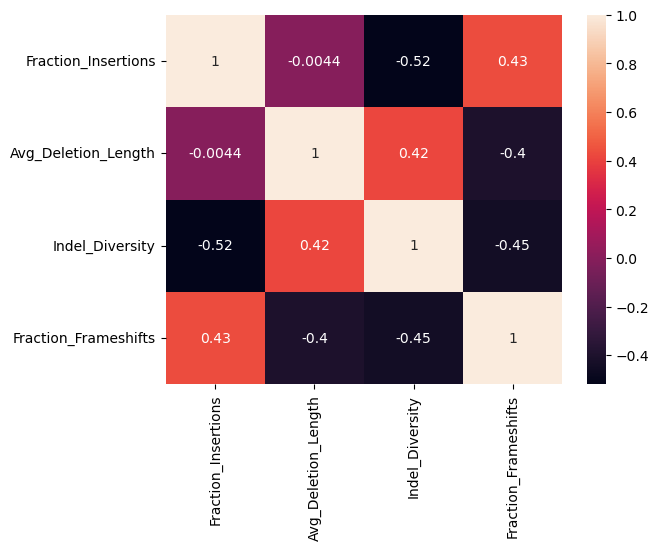

In [194]:
# Plot a correlation heatmap to check if there are strong correlations between the target variables.
sns.heatmap(train_df.iloc[:, 2:].corr(), annot=True)

From the heatmap, it can be seen that the highest correlation score among the four target variables is 0.52, while the others are all below 0.5. Using the commonly applied threshold of 0.7 to define strong correlations, it can be concluded that there is no strong correlation between the target variables.

In [197]:
# Separate features and target variables.
X_train = train_df['GuideSeq']
y_train = train_df[['Fraction_Insertions', 'Avg_Deletion_Length', 'Indel_Diversity', 'Fraction_Frameshifts']]

After exploring the data earlier, we can now preliminarily divide the data into feature variables and target variables to facilitate their independent preprocessing and feature engineering in subsequent steps.

# Feature Engineering

Since this study aims to predict the repair outcomes in CRISPR-Cas9 gene editing experiments based on the DNA sequences provided in the GuideSeq column, the feature engineering process involves encoding the sequences to better represent their local features. During the experimental research, the following four approaches were primarily used to extract features from the DNA sequences in the GuideSeq column.

### Approach 1: Analyze sequence k-mers.

In biology, a k-mer refers to a substring of length k from a biological sequence. For example, for a DNA sequence ACGAGGTACGA, its 4-mers are as shown in the diagram below.

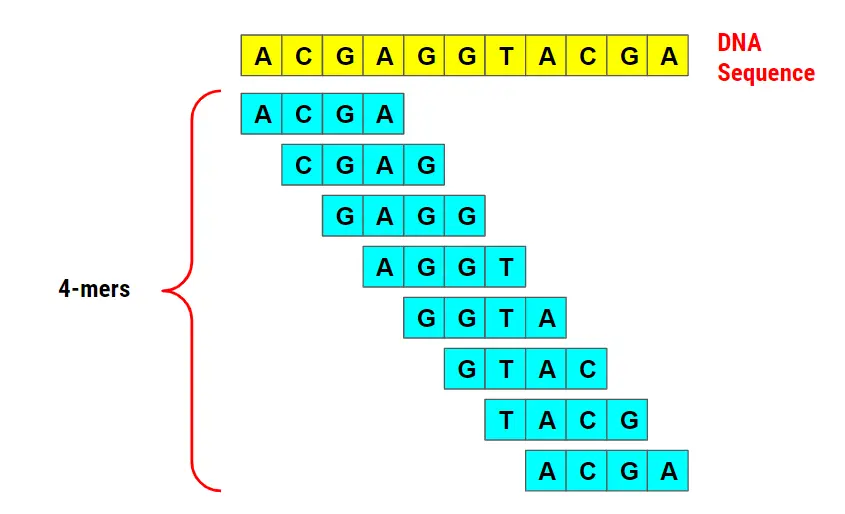

I saved this picture when I was learning about k-mers.

For this dataset, each DNA sequence consists of 23 bases, resulting in 23-k+1 k-mers. There are $4^k$ possible k-mers in total. In the following steps, the sequences are divided into fixed-length 3-mer fragments, and are then encoded.

In [204]:
# Define k-mer fragment length
k = 3

def get_kmers(sequence, k):
    return [sequence[i:i+k] for i in range(len(sequence) - k + 1)]

# Count the k-mers in each DNA sequence
kmer_features = []
for seq in train_df['GuideSeq']:
    kmers = get_kmers(seq, k)
    kmer_count = Counter(kmers)
    kmer_features.append(kmer_count)

# Represent k-mer features as a DataFrame
kmer_df_1 = pd.DataFrame(kmer_features)

# Standardize the length to ensure each sequence has the same number of features. 
# Because some sequences may lack certain k-mers, the corresponding column values in the DataFrame will be NaN.
kmer_df_1 = kmer_df_1.fillna(0)
kmer_df_1

,CTG,TGC,GCA,CAG,AGG,GGG,GGC,GCT,CTA,TAG,...,TAC,CGT,GGT,CGA,CTC,CTT,GTA,TAA,ACT,TCT
0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,2.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1061,1.0,0.0,0.0,1.0,2.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1062,1.0,0.0,0.0,2.0,1.0,2.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1063,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,2.0,...,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0


From the above results, it can be seen that 1,064 DNA sequences have been converted into 64 k-mer fragments. However, the performance evaluated on the validation set after using this result for model training was not optimal.

### Approach 2: One-hot Encoding

This feature extraction approach involves splitting each base in the sequence and performing 0-1 encoding.

For example, each position in the sequence can only have one of A, C, G, or T. In this case, each position in the DNA sequence can be represented by one of the following:
- A: [1,0,0,0]
- T: [0,1,0,0]
- G: [0,0,1,0]
- T: [0,0,0,1]

In [209]:
df = pd.DataFrame([[b for b in a] for a in X_train])

In [211]:
one_hot = pd.get_dummies(df, dtype=int)
one_hot

,0_A,0_C,0_G,0_T,1_A,1_C,1_G,1_T,2_A,2_C,...,19_A,19_C,19_G,19_T,20_A,20_C,20_G,20_T,21_G,22_G
0,0,1,0,0,0,0,0,1,0,0,...,0,0,0,1,1,0,0,0,1,1
1,0,0,1,0,1,0,0,0,0,0,...,0,0,0,1,0,0,1,0,1,1
2,0,0,1,0,0,1,0,0,1,0,...,0,0,0,1,0,1,0,0,1,1
3,0,0,1,0,0,0,0,1,0,1,...,1,0,0,0,0,0,1,0,1,1
4,1,0,0,0,0,0,0,1,1,0,...,1,0,0,0,0,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,1,0,0,0,0,0,0,1,0,0,...,0,1,0,0,1,0,0,0,1,1
1061,0,1,0,0,1,0,0,0,0,1,...,0,0,0,1,1,0,0,0,1,1
1062,0,0,1,0,0,0,1,0,0,0,...,1,0,0,0,0,0,1,0,1,1
1063,1,0,0,0,1,0,0,0,1,0,...,0,0,0,1,1,0,0,0,1,1


This approach yielded the best performance in subsequent model evaluations when approach 4 was not happened. (At the time, I didn’t fully understand some of the biological significance of this project. To be honest, even now, I think I’ve may only some of it. Otherwise, I thought I might have been able to find a key point to train the model better.)

This approach is not suitable for all scenarios because character-by-character one-hot encoding for long sequences can result in high-dimensional sparse matrices.

However, the sequence length here is 23, which is not a long sequence. So, this method has the advantage of adding some computational complexity without much impact on the model's ability to generalize.

### Approach 3: Word Embedding

In DNA sequence representation, the Word Embedding method represents DNA subsequences (k-mers) by mapping them to low-dimensional vectors. This approach can capture the contextual information within DNA sequences.

In [216]:
# Train a Word2Vec model using Gensim.
w2v_model = Word2Vec([get_kmers(_, 3) for _ in train_df['GuideSeq']], vector_size=50)

In [218]:
# Use the trained word embedding model to obtain the word vectors for each subsequence.
RES = []
for item in [get_kmers(_, 3) for _ in train_df['GuideSeq']]:
    vector = 0
    for _ in item:
        vector += w2v_model.wv[_]
    # Finally, save the average word vectors.
    RES.append(vector/23)

In [220]:
w2v = np.array(RES)
pd.DataFrame(w2v)

,0,1,2,3,4,5,6,7,8,9,...,40,41,42,43,44,45,46,47,48,49
0,0.103373,0.054363,0.120722,0.251437,-0.155577,-0.039249,0.361633,0.243120,-0.095060,-0.106823,...,0.405917,-0.145319,0.029597,0.033971,0.308942,-0.225643,-0.024282,-0.204633,0.186983,0.226057
1,0.103790,0.051973,0.118094,0.244185,-0.160569,-0.045424,0.362589,0.233698,-0.090101,-0.111066,...,0.402450,-0.136851,0.036796,0.031083,0.310327,-0.220089,-0.018071,-0.210650,0.179177,0.219417
2,0.107303,0.054392,0.120833,0.243460,-0.164936,-0.048790,0.359184,0.239578,-0.093446,-0.112237,...,0.405161,-0.140461,0.043309,0.029739,0.315661,-0.230262,-0.022794,-0.205662,0.184103,0.224699
3,0.110590,0.050326,0.122767,0.243821,-0.162040,-0.047120,0.358934,0.234640,-0.093503,-0.108353,...,0.404122,-0.140898,0.041538,0.026898,0.311069,-0.220226,-0.024477,-0.204483,0.184476,0.221553
4,0.108912,0.052528,0.116356,0.244618,-0.161452,-0.047252,0.360322,0.239489,-0.097377,-0.115759,...,0.400092,-0.141835,0.036490,0.029977,0.310142,-0.225563,-0.021542,-0.201096,0.182933,0.223839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,0.100084,0.049149,0.112530,0.242615,-0.161123,-0.046591,0.362765,0.235233,-0.091133,-0.119382,...,0.399886,-0.132337,0.033537,0.026810,0.311537,-0.223078,-0.017178,-0.207785,0.184949,0.220569
1061,0.094414,0.055647,0.121478,0.245725,-0.160172,-0.048605,0.355684,0.233308,-0.090611,-0.118368,...,0.398237,-0.138063,0.033559,0.034784,0.314025,-0.224074,-0.022746,-0.205923,0.187456,0.219887
1062,0.104967,0.051939,0.116844,0.242412,-0.155406,-0.046681,0.356225,0.238296,-0.090468,-0.115465,...,0.400648,-0.141529,0.034985,0.030458,0.307378,-0.218668,-0.020513,-0.205085,0.181995,0.221143
1063,0.097135,0.053064,0.119716,0.250269,-0.156844,-0.043400,0.358047,0.237598,-0.095051,-0.109032,...,0.407409,-0.139086,0.036438,0.034968,0.309463,-0.226363,-0.026800,-0.210189,0.187291,0.222361


The feature representation results using word embeddings are shown above, and the dimensionality of the word vectors can be controlled through the vector_size parameter.

However, subsequent validation showed that this approach is not the optimal feature engineering method. This may be because, although this method can capture the contextual information in DNA sequences, it is less effective at capturing complex patterns in the sequences since the genetic sequences in this dataset are not long.

### Approach 4: Calculate GC content and Combine it with the One-hot Feature Matrix.

Calculate the proportion of G and C in the sequence. GC content can affect the physical properties of DNA and its repair probability.

In [225]:
# Define a function to calculate GC content.
def calculate_gc_content(sequence):
    g_count = sequence.count('G')
    c_count = sequence.count('C')
    gc_content = (g_count + c_count) / len(sequence)
    return gc_content

In [227]:
# Apply this function to calculate the GC content of each sequence.
one_hot['GC_Content'] = X_train.apply(calculate_gc_content)

In [229]:
one_hot

,0_A,0_C,0_G,0_T,1_A,1_C,1_G,1_T,2_A,2_C,...,19_C,19_G,19_T,20_A,20_C,20_G,20_T,21_G,22_G,GC_Content
0,0,1,0,0,0,0,0,1,0,0,...,0,0,1,1,0,0,0,1,1,0.521739
1,0,0,1,0,1,0,0,0,0,0,...,0,0,1,0,0,1,0,1,1,0.695652
2,0,0,1,0,0,1,0,0,1,0,...,0,0,1,0,1,0,0,1,1,0.521739
3,0,0,1,0,0,0,0,1,0,1,...,0,0,0,0,0,1,0,1,1,0.565217
4,1,0,0,0,0,0,0,1,1,0,...,0,0,0,0,0,1,0,1,1,0.434783
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1060,1,0,0,0,0,0,0,1,0,0,...,1,0,0,1,0,0,0,1,1,0.565217
1061,0,1,0,0,1,0,0,0,0,1,...,0,0,1,1,0,0,0,1,1,0.608696
1062,0,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,1,1,0.608696
1063,1,0,0,0,1,0,0,0,1,0,...,0,0,1,1,0,0,0,1,1,0.478261


From the operations in this approach, we know that after calculating the GC content, it was added as an additional feature to the one-hot encoded feature matrix from Approach 2. This enriched the feature representation, thereby improving the model's ability to predict repair probability. Subsequent model validation confirmed that Approach 4 outperformed Approach 2 in evaluation metrics on the validation set, making Approach 4 the final feature engineering method adopted in this study.

# Modeling

### Feature Standardization

In regression tasks, standardization can reduce the impact of outliers or features with large differences in range on the model, making the model more robust. It allows the model to more fairly weigh each feature, improving the accuracy of predicting repair outcomes.

In [235]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(one_hot)
X_scaled

array([[-0.52046427,  1.88448456, -0.71009668, ...,  0.        ,
         0.        , -0.21050205],
       [-0.52046427, -0.53064908,  1.40825895, ...,  0.        ,
         0.        ,  1.86048807],
       [-0.52046427, -0.53064908,  1.40825895, ...,  0.        ,
         0.        , -0.21050205],
       ...,
       [-0.52046427, -0.53064908,  1.40825895, ...,  0.        ,
         0.        ,  0.82499301],
       [ 1.92136148, -0.53064908, -0.71009668, ...,  0.        ,
         0.        , -0.72824958],
       [-0.52046427, -0.53064908, -0.71009668, ...,  0.        ,
         0.        ,  1.34274054]])

The reason for standardizing the target variables below is that during the data exploration phase, it was found that the range of values for the four target variables differed significantly. Therefore, numerical standardization of the target variables was considered. However, after subsequent model validation, it was found that standardizing the target variables had no impact on the evaluation metrics. As a result, the unstandardized target variables were used in the final training and validation set splits.

In [238]:
y_scaler = StandardScaler()
y_scaled = y_scaler.fit_transform(y_train)
y_scaled

array([[-0.91102966, -1.02236902, -0.37254268,  0.88299867],
       [ 0.51055058,  1.14715765,  0.09918752, -0.26545503],
       [-0.47145483,  0.83882976,  0.18395821, -0.11041314],
       ...,
       [ 1.38270972, -0.00199523, -0.88099881,  1.09051813],
       [-0.01987804,  0.17890308, -0.02568084, -1.37858094],
       [ 0.48754345,  0.26457638,  0.27142709,  0.57660618]])

### Model Training

In the model training process, I tried some machine learning regression models: RandomForestRegressor, AdaBoostRegressor, SVR, BayesianRidge, XGBRegressor. The final online evaluation results showed that the model with the highest score was the GradientBoostingRegressor wrapped in a MultiOutputRegressor. The reason for choosing this model is:
- GradientBoostingRegressor is a tree-based model that follows the gradient boosting framework, and it can handle nonlinear relationships between features effectively, which traditional linear models may not be able to capture.
- GradientBoostingRegressor can adaptively split decision trees based on the data, automatically selecting important features and ignoring irrelevant ones.
- GradientBoostingRegressor is not sensitive to the distribution of features and performs well when dealing with data that contains outliers or noise.
- Each target variable may have different distributions or characteristics. MultiOutputRegressor can optimize each target variable separately, without forcing the assumption that they share a common underlying model.
- From the initial data exploration, it is clear that there is no strong correlation between the target variables. MultiOutputRegressor avoids forcing a model to capture relationships between the targets, thereby reducing interference between the variables.

In [242]:
# Split the data into training and validation sets.
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(X_scaled, y_train, test_size=0.2, random_state=42)

In [244]:
# Model definition
model = MultiOutputRegressor(GradientBoostingRegressor(random_state=60))

# Train the model
model.fit(X_train_split, y_train_split)

# Validate the model
y_pred = model.predict(X_val_split)

# Calculate performance metrics
mse = mean_squared_error(y_val_split, y_pred)
print("Mean Squared Error on Validation Set:", mse)
r2 = r2_score(y_val_split, y_pred)
print("Validation R²: {}".format(r2))

Mean Squared Error on Validation Set: 2.497730812407803
Validation R²: 0.2266450120780169


### Model Hyperparameter Tuning

Reasons for adjusting the n_estimators and learning_rate parameters:
- There is a complementary relationship between n_estimators and learning_rate. A higher learning_rate typically requires a smaller n_estimators to avoid overfitting, while a lower learning_rate generally needs a larger n_estimators to ensure the model has enough learning capacity.
- n_estimators controls the number of weak learners in gradient boosting, determining the overall complexity and learning capacity of the model.
- learning_rate determines the contribution weight of each tree to the final prediction, controlling the training speed and model stability.

In [248]:
for a in [100, 200, 300, 500]:
    for b in [0.01, 0.05, 0.1]:
        model = MultiOutputRegressor(GradientBoostingRegressor(n_estimators=a, learning_rate=b, random_state=42))

        # Train the model
        model.fit(X_train_split, y_train_split)
        
        # Validate the model
        y_pred = model.predict(X_val_split)
        
        # Calculate performance metrics
        r2 = r2_score(y_val_split, y_pred)
        print("n_estimators={},learning_rate={} Validation R²: {}".format(a, b, r2))

n_estimators=100,learning_rate=0.01 Validation R²: 0.13050388886368283
n_estimators=100,learning_rate=0.05 Validation R²: 0.22722403677204017
n_estimators=100,learning_rate=0.1 Validation R²: 0.2246721537104327
n_estimators=200,learning_rate=0.01 Validation R²: 0.1843451768537242
n_estimators=200,learning_rate=0.05 Validation R²: 0.22515301590107817
n_estimators=200,learning_rate=0.1 Validation R²: 0.1997565541055057
n_estimators=300,learning_rate=0.01 Validation R²: 0.21002526981489536
n_estimators=300,learning_rate=0.05 Validation R²: 0.21603224114317676
n_estimators=300,learning_rate=0.1 Validation R²: 0.17741725812011264
n_estimators=500,learning_rate=0.01 Validation R²: 0.2265321681187839
n_estimators=500,learning_rate=0.05 Validation R²: 0.19077243928192741
n_estimators=500,learning_rate=0.1 Validation R²: 0.14308070353737304


During further tuning of the n_estimators and learning_rate parameters for the GradientBoostingRegressor, it was found that models trained with n_estimators=100, learning_rate=0.05 and n_estimators=500, learning_rate=0.01 had higher scores on the validation set compared to the model without tuning. However, the scores for the models were slightly worse in the online evaluation. The possible reason is that the validation set used for parameter tuning was not the same as the online evaluation dataset, so the optimal model cannot be fully determined based on the parameter combinations derived from the validation set.

### Train the Optimal Model

Since the final goal is to submit the prediction results on the test set for evaluation, the model needs to be retrained using the optimal parameters on the entire training dataset (which hasn't been split yet) for later use in predicting the test set.

In [252]:
best_model = MultiOutputRegressor(GradientBoostingRegressor(random_state=60))
best_model.fit(X_scaled, y_train)

MultiOutputRegressor(estimator=GradientBoostingRegressor(random_state=60))

# Test the Model and Generate the Submission File

At this stage, the test data needs to finish the same feature extraction process as the training set.

In [255]:
# Load the test data.
test_df = pd.read_csv('test.csv')

test_kmer_df = pd.get_dummies(pd.DataFrame([[b for b in a] for a in test_df['GuideSeq']]))

In [256]:
test_kmer_df['GC_Content'] = test_df['GuideSeq'].apply(calculate_gc_content)

To ensure consistency in data preprocessing, the test set must be standardized based on the same statistics as the training set, otherwise, it may lead to a mismatch in the distribution between the test data and the training data.

In [258]:
# Standardize the test set data.
X_test_scaled = scaler.transform(test_kmer_df)

In [259]:
# Generate predictions using the optimal model.
y_test_pred = best_model.predict(X_test_scaled)

# Save the prediction results.
submission_df = pd.DataFrame(y_test_pred, columns=['Fraction_Insertions', 'Avg_Deletion_Length', 'Indel_Diversity', 'Fraction_Frameshifts'])
submission_df['Id'] = test_df['Id']
submission_df = submission_df[['Id', 'Fraction_Insertions', 'Avg_Deletion_Length', 'Indel_Diversity', 'Fraction_Frameshifts']]

# Save the results as a CSV file.
submission_df.to_csv('submission.csv', index=False)

In [262]:
submission_df

,Id,Fraction_Insertions,Avg_Deletion_Length,Indel_Diversity,Fraction_Frameshifts
0,0,0.192662,7.489399,3.955767,0.705467
1,1,0.305099,5.955811,3.182945,0.768665
2,2,0.186604,7.112617,3.704001,0.653319
3,3,0.303217,7.597012,3.605713,0.758477
4,4,0.205397,7.278569,3.942093,0.656878
...,...,...,...,...,...
299,299,0.100331,6.531784,3.815942,0.691844
300,300,0.136149,7.911897,3.766994,0.693506
301,301,0.195051,7.400941,4.020934,0.747441
302,302,0.244324,8.772251,4.245669,0.698614
